# Task B: Emotion Detection - Exploratory Data Analysis

**Project:** Sentiment and Emotion Analysis Using Machine Learning (Phase 1)
**Dataset:** [dair-ai/emotion](https://huggingface.co/datasets/dair-ai/emotion), `split`
configuration: English Twitter messages labelled with six emotions, **sadness (0)**, **joy (1)**,
**love (2)**, **anger (3)**, **fear (4)** and **surprise (5)** (CARER, Saravia et al., 2018).

This notebook examines the data before any modelling:

1. Load the data
2. Data quality: empty texts, duplicates, conflicting labels, leakage between splits
3. Class distribution
4. Text length
5. Text characteristics
6. Vocabulary
7. Distinctive words per class
8. Summary and implications for Phase 2 (TF-IDF + Logistic Regression)

Figures are saved to `reports/figures/`. If `data/raw/emotion/` is empty, run
`python src/download_data.py` first. The analysis helpers live in `src/eda.py`, so the sentiment
and emotion notebooks use identical methods.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Make src/ importable whether the notebook runs from notebooks/ or the project root.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import eda  # noqa: E402

eda.set_plot_style()
pd.set_option("display.max_colwidth", 110)
DATASET, NAME = "emotion", "Emotion"
print(f"Python {sys.version.split()[0]}, pandas {pd.__version__}")

Python 3.12.10, pandas 3.1.0


## 1. Load the data

In [2]:
splits = eda.load_splits(DATASET)
labels = eda.label_order(splits)
train = eda.add_length_columns(splits["train"])

print("Classes in label-id order:", labels)
pd.DataFrame({split: [f"{len(df):,}", ", ".join(df.columns)] for split, df in splits.items()},
             index=["rows", "columns"])

Classes in label-id order: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


,train,validation,test
rows,"16,000","2,000","2,000"
columns,"text, label, label_name","text, label, label_name","text, label, label_name"


In [3]:
# Two random training examples per class
splits["train"].groupby("label", group_keys=False).sample(2, random_state=42)[["label_name", "text"]]

,label_name,text
11433,sadness,im feeling so lousy they tried to cheer me up during school time and during choir practice
9343,sadness,i feel highly disadvantaged
2825,joy,i feel very relaxed playing with carl clarke says
1607,joy,i feel better now
3067,love,i don t feel respect i don t feel admiration and i don t feel an entirely romantic tone
5051,love,i feel that if i make one mistake everything will shatter like a delicate crystal flower that slipped from...
10995,anger,i needed to feel rebellious
15792,anger,i practically got the feeling of a hostile environment
5765,fear,i wish i could open up to people not feel so terrified of reactions and opinions
6179,fear,i just feel skeptical


Each CSV has three columns: the message `text`, the integer `label` and its readable `label_name`.
There are 16,000 training texts and 2,000 each for validation and test. Unlike TweetEval, the texts
are already preprocessed (see section 5).

## 2. Data quality

Checks for empty texts, texts that appear more than once, identical texts with different labels, and
texts shared between splits (which would leak test information into training).

In [4]:
display(eda.quality_checks(splits))
display(eda.split_overlap(splits))
print("Distinct texts found in more than one split:", eda.texts_in_several_splits(splits))

,rows,empty_texts,repeated_texts,conflicting_label_texts
split,,,,
train,16000,0,31,30
validation,2000,0,2,2
test,2000,0,0,0


,shared_texts
splits,
train & validation,5
train & test,11
validation & test,3


Distinct texts found in more than one split: 19


In [5]:
# Identical training texts that carry different labels
eda.conflicting_examples(splits["train"], n=8)

,text,label_name
3508,i am not amazing or great at photography but i feel passionate about it,joy
8246,i am not amazing or great at photography but i feel passionate about it,love
5277,i began to feel accepted by gaia on her own terms,love
15705,i began to feel accepted by gaia on her own terms,joy
8804,i bet taylor swift basks in the knowledge that the boys she writes songs about probably feel tortured,fear
15572,i bet taylor swift basks in the knowledge that the boys she writes songs about probably feel tortured,anger
11013,i cant escape the tears of sadness and just true grief i feel at the loss of my sweet friend and sister,love
12892,i cant escape the tears of sadness and just true grief i feel at the loss of my sweet friend and sister,joy


In [6]:
# Which labels do the conflicting duplicates disagree on?
train_raw = splits["train"]
conflicted = train_raw[train_raw.groupby("text")["label"].transform("nunique") > 1]
pairs = conflicted.groupby("text")["label_name"].agg(lambda s: " / ".join(sorted(set(s))))
pairs.value_counts().to_frame("texts")

,texts
label_name,
joy / love,15
fear / surprise,6
anger / fear,4
anger / sadness,3
joy / surprise,1
fear / sadness,1


**Findings**

- No empty texts.
- Duplicates are rare but almost always disagree: train has 31 repeated copies of texts, and 30
  distinct texts appear with more than one label. The disagreements are between related emotions,
  mostly joy/love (15) and fear/surprise (6): the same pairs a classifier is likely to confuse.
- 19 distinct texts appear in more than one split, 11 of them in both train and test (0.55% of
  test). This is a small leakage risk; it is noted here, and the official splits are kept so results
  stay comparable.

## 3. Class distribution


The *class-mix shift* is the total variation distance between two class distributions: the
percentage of examples whose class would have to change to turn one distribution into the other.

In [7]:
counts = eda.class_counts(splits, labels)
display(pd.concat({"examples": counts, "share (%)": eda.class_shares(counts)}, axis=1))
print(f"Largest : smallest class in train      {eda.imbalance_ratio(counts):.1f} : 1")
print(f"Class-mix shift, train vs validation   {eda.distribution_shift(counts, 'train', 'validation'):.1f} points")
print(f"Class-mix shift, train vs test         {eda.distribution_shift(counts, 'train', 'test'):.1f} points")

examples                 share (%)                 
            train validation test     train validation  test
class                                                       
sadness      4666        550  581      29.2       27.5  29.0
joy          5362        704  695      33.5       35.2  34.8
love         1304        178  159       8.2        8.9   8.0
anger        2159        275  275      13.5       13.8  13.8
fear         1937        212  224      12.1       10.6  11.2
surprise      572         81   66       3.6        4.0   3.3

Largest : smallest class in train      9.4 : 1
Class-mix shift, train vs validation   3.2 points
Class-mix shift, train vs test         1.5 points


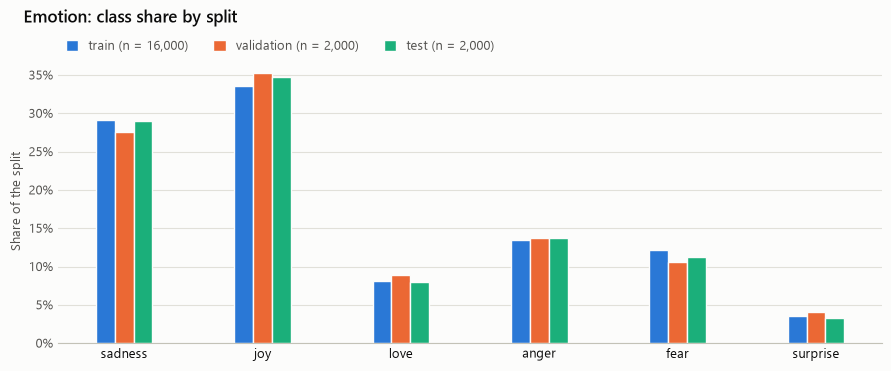

In [8]:
fig = eda.plot_class_distribution(counts, f"{NAME}: class share by split")
eda.save_figure(fig, f"{DATASET}_class_distribution")
plt.show()

**Findings**

- Strong imbalance: `joy` (33.5%) and `sadness` (29.2%) make up almost two-thirds of train, while
  `love` (8.2%) and `surprise` (3.6%) are small: a 9.4 : 1 ratio between the largest and smallest
  class.
- All three splits share the same class mix (1.5-point shift between train and test, 3.2 between
  train and validation), so validation scores should be a good guide to test scores.
- Consequences for Phase 2: accuracy would hide poor performance on `surprise` and `love`. Report
  macro-F1 and per-class recall, and try `class_weight="balanced"`.

## 4. Text length

Length is measured in characters and in whitespace-separated words.

In [9]:
display(eda.length_summary(train))
eda.length_summary(train, labels)

,words_mean,words_median,words_p95,words_max,chars_mean,chars_median,chars_p95,chars_max
all,19.2,17.0,41.0,66.0,96.8,86.0,207.0,300.0


,words_mean,words_median,words_p95,words_max,chars_mean,chars_median,chars_p95,chars_max
class,,,,,,,,
sadness,18.4,16.0,41.0,66.0,92.6,80.0,206.0,299.0
joy,19.5,18.0,40.0,64.0,98.6,89.0,206.9,300.0
love,20.7,19.0,41.0,63.0,104.0,94.0,207.0,299.0
anger,19.2,17.0,41.0,62.0,96.9,85.0,210.0,298.0
fear,18.8,17.0,41.0,60.0,96.1,85.0,205.4,296.0
surprise,20.0,18.0,42.0,60.0,101.7,88.5,214.0,287.0


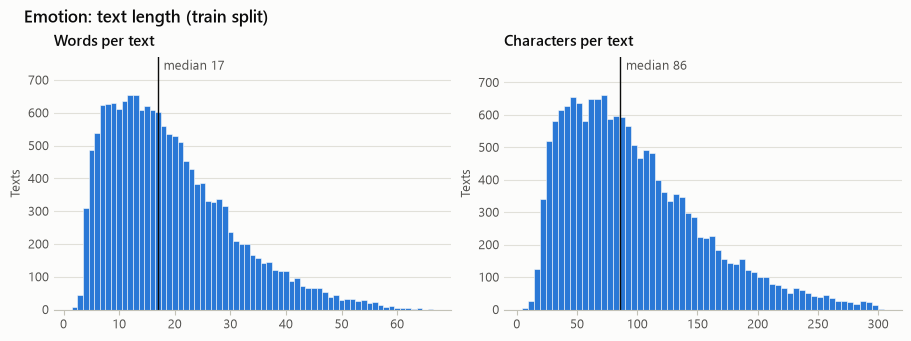

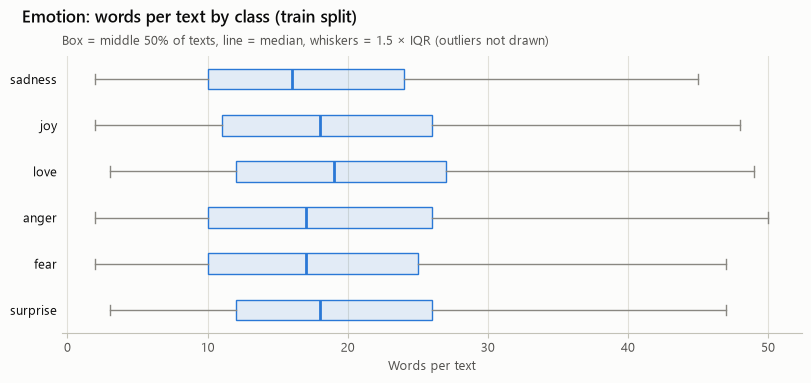

In [10]:
fig = eda.plot_length_distribution(train, f"{NAME}: text length (train split)")
eda.save_figure(fig, f"{DATASET}_text_length")
plt.show()

fig = eda.plot_length_by_class(train, labels, f"{NAME}: words per text by class (train split)")
eda.save_figure(fig, f"{DATASET}_length_by_class")
plt.show()

**Findings**

- Median 17 words (86 characters), with a long tail: 95% of texts have at most 41 words and the
  longest has 66 (300 characters). These texts are longer and more varied than the TweetEval
  tweets.
- Length is similar across classes (median 16-19 words), so it carries little class information.

## 5. Text characteristics

Which elements appear in the text? This decides the preprocessing needed in Phase 2.

In [11]:
# Percentage of training texts in each class that contain each feature
eda.pattern_shares(train, labels)

label_name,sadness,joy,love,anger,fear,surprise,all
feature,,,,,,,
@user mention,0.0,0.0,0.0,0.0,0.0,0.0,0.0
hashtag,0.0,0.0,0.0,0.0,0.0,0.0,0.0
URL or http,1.4,1.5,1.7,0.7,0.4,1.4,1.2
HTML entity (e.g. &amp;),0.0,0.0,0.0,0.0,0.0,0.0,0.0
escaped character (e.g. \u2019),0.0,0.0,0.0,0.0,0.0,0.0,0.0
number,0.0,0.0,0.0,0.0,0.0,0.0,0.0
uppercase letter,0.0,0.0,0.0,0.0,0.0,0.0,0.0
! or ?,0.0,0.0,0.0,0.0,0.0,0.0,0.0
apostrophe,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [12]:
# The few texts containing "http" hold leftover HTML markup rather than links
splits["train"].loc[splits["train"]["text"].str.contains("http"), "text"].head(3).tolist()

['i feel they are pretty safe on my blog img src http s',
 'i stopped feeling so exhausted a href http provokingbeauty',
 'i feel so dazed a href http twitter']

**Findings**

- The text is pre-cleaned: no uppercase letters, numbers, punctuation, apostrophes (contractions
  appear as *im*, *dont*, *didnt*), hashtags or mentions. No extra normalisation is needed in
  Phase 2.
- 98.7% of texts contain a form of *feel* ("i feel ...", "feeling"), so these words carry no class
  information; IDF weighting will down-weight them automatically.
- The 1.2% of texts containing "http" hold remnants of HTML markup (*a href http ...*), not real
  links. They are rare enough to ignore.

## 6. Vocabulary

Words are lowercase alphabetic tokens.

In [13]:
word_counts = eda.word_counts(train["text"])
pd.Series(eda.vocabulary_summary(word_counts), name="train").map("{:,}".format).to_frame()

,train
tokens,"306,661"
vocabulary,"15,212"
seen_once,"7,813"
words_for_90pct,"1,782"
words_for_95pct,"4,179"


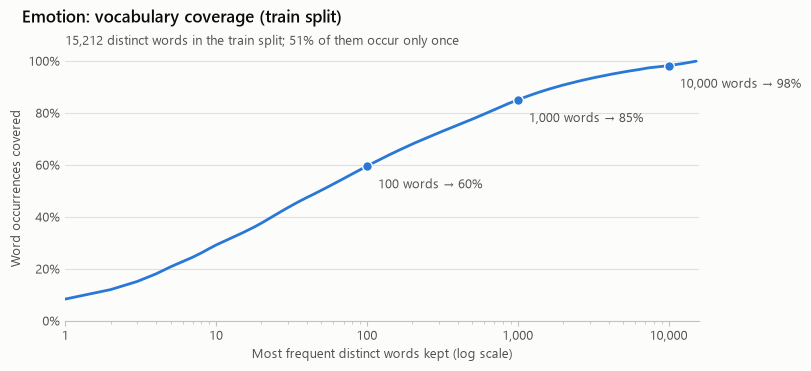

In [14]:
fig = eda.plot_vocabulary_coverage(word_counts, f"{NAME}: vocabulary coverage (train split)")
eda.save_figure(fig, f"{DATASET}_vocabulary_coverage")
plt.show()

In [15]:
# Most frequent words per class after removing stop words
eda.top_words(train, labels, n=10)

,sadness,joy,love,anger,fear,surprise
rank,,,,,,
1,feel,feel,feel,feel,feel,feel
2,feeling,feeling,feeling,feeling,feeling,feeling
3,like,like,like,like,like,like
4,just,just,love,just,just,amazed
5,really,really,just,really,little,impressed
6,know,time,really,time,bit,overwhelmed
7,time,know,know,know,know,weird
8,little,make,sweet,little,really,just
9,want,want,loving,people,people,surprised


**Findings**

- 15,212 distinct words, 51% of which occur only once; the 4,179 most frequent words cover 95% of
  word occurrences, so roughly 4,000-5,000 TF-IDF features keep almost all of the text.
- The most frequent words (*feel, feeling, like, just, really*) are shared by every class; only a
  few class-specific words (such as *love*, *amazed* and *impressed*) reach the top-10 lists.

## 7. Distinctive words per class

Raw counts favour words that are common in every class. Instead, each class's words are ranked by
how many times more frequent they are in that class than in the other classes (add-one smoothing,
stop words removed, only words used at least 25 times). Words are shown exactly as they occur in the
data.

In [16]:
distinctive = eda.distinctive_words(train, labels)
pd.DataFrame({lab: [f"{w} ({r:.0f}×)" for w, r in zip(t["word"], t["ratio"])]
              for lab, t in distinctive.items()},
             index=pd.RangeIndex(1, 11, name="rank"))

,sadness,joy,love,anger,fear,surprise
rank,,,,,,
1,gloomy (146×),superior (105×),sympathetic (548×),envious (223×),apprehensive (414×),impressed (452×)
2,disheartened (139×),festive (103×),horny (460×),offended (195×),shaken (228×),dazed (361×)
3,inadequate (129×),clever (101×),fond (401×),dissatisfied (170×),distressed (225×),amazed (298×)
4,listless (124×),resolved (97×),loyal (220×),bitchy (158×),suspicious (218×),curious (241×)
5,unimportant (124×),energetic (96×),tender (144×),rebellious (142×),pressured (200×),shocked (144×)
6,deprived (121×),intelligent (96×),longing (127×),greedy (132×),distraught (190×),surprised (111×)
7,unfortunate (121×),virtuous (88×),nostalgic (120×),resentful (126×),shaky (172×),funny (52×)
8,doomed (119×),artistic (86×),delicate (96×),dangerous (114×),reluctant (140×),weird (16×)
9,submissive (101×),invigorated (84×),gentle (88×),hostile (96×),frantic (133×),overwhelmed (16×)


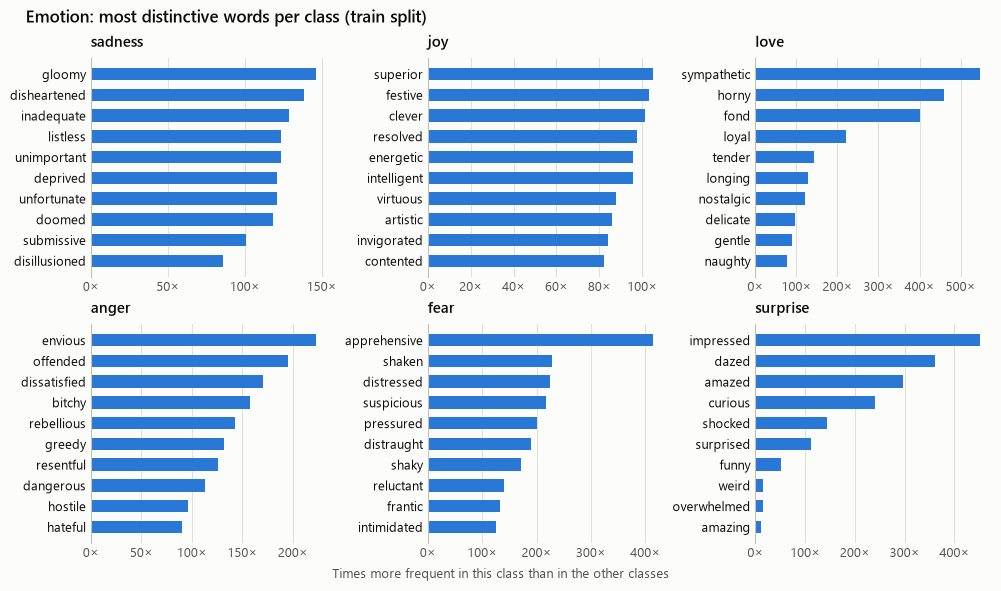

In [17]:
fig = eda.plot_distinctive_words(distinctive, labels, f"{NAME}: most distinctive words per class (train split)")
eda.save_figure(fig, f"{DATASET}_distinctive_words")
plt.show()

**Findings**

- Every class has words that occur almost only in that class, far stronger cues than in TweetEval
  (strongest ratios of about 100-550×, against at most about 30× there). For example: sadness
  *gloomy, disheartened*; joy *festive, energetic*; love *sympathetic, fond, tender*; anger *envious,
  offended*; fear *apprehensive, shaken*; surprise *impressed, dazed, amazed*.
- The labels are therefore closely tied to specific emotion words, typically in the pattern
  "i feel *emotion word*". A TF-IDF + Logistic Regression model should perform well, but it may learn
  these keywords rather than context, which is worth checking on misclassified examples in Phase 2.
- Some word-label pairings are not obvious (*superior* and *clever* for joy, *sympathetic* for
  love), so the labels follow the dataset's own conventions rather than everyday intuition.

## 8. Summary and implications for Phase 2

| Finding | Implication for Phase 2 |
|---|---|
| Strong imbalance (9.4 : 1), consistent across splits | Report macro-F1 and per-class recall; compare `class_weight=None` and `"balanced"`; validation is a reliable guide to test |
| Text already lowercased and stripped of punctuation | No normalisation needed beyond what TF-IDF does |
| A form of *feel* in 98.7% of texts | Leave it to IDF weighting; no custom stop-word list needed |
| 30 texts with conflicting labels, mostly joy/love and fear/surprise | Drop them from train; expect these pairs in the confusion matrix |
| 19 texts shared across splits | Keep the official splits; mention the small overlap when reporting |
| 15k distinct words, 51% seen once; 4.2k cover 95% | Start from unigrams + bigrams, `min_df=2`, `max_features` of about 5,000, then tune on validation |
| Very strong keyword cues | Expect high scores; check errors for over-reliance on keywords |

The combined summary of both datasets is in `reports/dataset_summary.md`.